# RMDS Hackathon: Dataset B (H1N1 vaccine acceptance, minimising the town's total cost)

**Task:** predict *exactly which people will accept a vaccine*, so the town's total spend
(vaccine costs + expected hospitalisation costs) is as low as possible. We submit our 5 best results.

**Run the cells top to bottom** (Runtime > Run all also works).

| Step | What happens | Hackathon task it covers |
|---|---|---|
| 1-3 | Setup, load data, first look | Data exploration |
| 4 | Exploratory data analysis (EDA) | Data exploration |
| 5 | Prepare columns | Pre-processing |
| 6-7 | Hospitalisation estimates (generative AI) and the town's **total-cost metric** | Evaluation metric |
| 8 | Compare 5 pre-processing options | Pre-processing |
| 9 | Compare 7+ different models with cross-validation | Modelling |
| 10 | Hyper-parameter tuning and hold-out validation | Performance analysis |
| 11 | Build candidates, rank by total cost, cross-validated spread | Performance analysis and submission |
| 12 | Robustness check under different hospitalisation assumptions | Performance analysis |
| 13 | Explainable AI (permutation importance, partial dependence, who gets flagged) | XAI |
| 14 | Plain-English summary for non-experts | Presentation |
| 15 | Save the 5 submission files | Submission |

## Step 1: Setup and imports

In [1]:
import os
import shutil
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import clone
from sklearn.model_selection import (train_test_split, StratifiedKFold,
                                     RandomizedSearchCV, GridSearchCV)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.ensemble import (RandomForestClassifier, ExtraTreesClassifier,
                              HistGradientBoostingClassifier)
from sklearn.metrics import roc_auc_score, log_loss, accuracy_score
from sklearn.inspection import permutation_importance, PartialDependenceDisplay

# XGBoost and LightGBM are pre-installed in Colab; if missing we simply skip them
try:
    from xgboost import XGBClassifier
except Exception:
    XGBClassifier = None
try:
    from lightgbm import LGBMClassifier
except Exception:
    LGBMClassifier = None

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42
print("Setup complete | XGBoost available:", XGBClassifier is not None,
      "| LightGBM available:", LGBMClassifier is not None)

Setup complete | XGBoost available: True | LightGBM available: True


## Step 2: Load data
In Colab a file picker appears. Select all three CSV files at once:
`dataset_B_training.csv`, `dataset_B_testing.csv`, `dataset_B_example_submission.csv`.
(If the files are already in the working folder, the upload is skipped.)

In [2]:
FILES = ["dataset_B_training.csv", "dataset_B_testing.csv", "dataset_B_example_submission.csv"]

if not all(os.path.exists(f) for f in FILES):
    try:
        from google.colab import files
        files.upload()
    except ImportError:
        raise FileNotFoundError("Place the three CSV files in the working folder first.")

train = pd.read_csv("dataset_B_training.csv")
test = pd.read_csv("dataset_B_testing.csv")
example = pd.read_csv("dataset_B_example_submission.csv")

print("train:", train.shape, "| test:", test.shape, "| example submission:", example.shape)

train: (4756, 31) | test: (4749, 30) | example submission: (4749, 2)


## Step 3: First look at the data

In [3]:
TARGET = "h1n1_vaccine"
ID = "respondent_id"

display(train.head())
print("Columns only in train:", set(train.columns) - set(test.columns))
print("Columns only in test: ", set(test.columns) - set(train.columns))
print("Duplicate IDs in train:", train[ID].duplicated().sum(),
      "| IDs shared by train and test:", len(set(train[ID]) & set(test[ID])))
print()
print("Target distribution (share of each class):")
print(train[TARGET].value_counts(normalize=True).round(3))

,respondent_id,h1n1_concern,h1n1_knowledge,behavioral_antiviral_meds,behavioral_avoidance,behavioral_face_mask,behavioral_wash_hands,behavioral_large_gatherings,behavioral_outside_home,behavioral_touch_face,...,income_poverty,marital_status,rent_or_own,employment_status,census_msa,household_adults,household_children,employment_sector,number_chronic_med_conditions,h1n1_vaccine
0,1,1.0,2.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,...,"<= $75,000, Above Poverty",Married,Own,Employed,"MSA, Not Principle City",2.0,1.0,science,0,0
1,2,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,Below Poverty,Not Married,Own,Employed,Non-MSA,0.0,3.0,wholesale,0,0
2,3,2.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,...,"> $75,000",Not Married,Own,Employed,"MSA, Principle City",0.0,0.0,education,0,1
3,4,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,...,"<= $75,000, Above Poverty",Not Married,Rent,Not in Labor Force,Non-MSA,0.0,0.0,NaN,0,0
4,5,2.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,NaN,Not Married,NaN,Unemployed,Non-MSA,3.0,0.0,NaN,0,0


Columns only in train: {'h1n1_vaccine'}
Columns only in test:  set()
Duplicate IDs in train: 0 | IDs shared by train and test: 0

Target distribution (share of each class):
h1n1_vaccine
0    0.606
1    0.394
Name: proportion, dtype: float64


In [4]:
miss = pd.DataFrame({
    "train_missing": train.isna().sum(),
    "train_missing_%": (train.isna().mean() * 100).round(1),
    "test_missing": test.isna().sum().reindex(train.columns),
})
display(miss[miss.train_missing > 0].sort_values("train_missing", ascending=False))

,train_missing,train_missing_%,test_missing
employment_sector,2364,49.7,2405.0
health_insurance,1925,40.5,1982.0
income_poverty,712,15.0,797.0
doctor_recc_h1n1,319,6.7,345.0
rent_or_own,315,6.6,379.0
employment_status,235,4.9,277.0
marital_status,226,4.8,269.0
education,224,4.7,269.0
child_under_6_months,134,2.8,155.0
health_worker,131,2.8,149.0


## Step 4: Exploratory data analysis (EDA)
The plots below help us decide how to handle missing values, which features matter, and how to encode them.

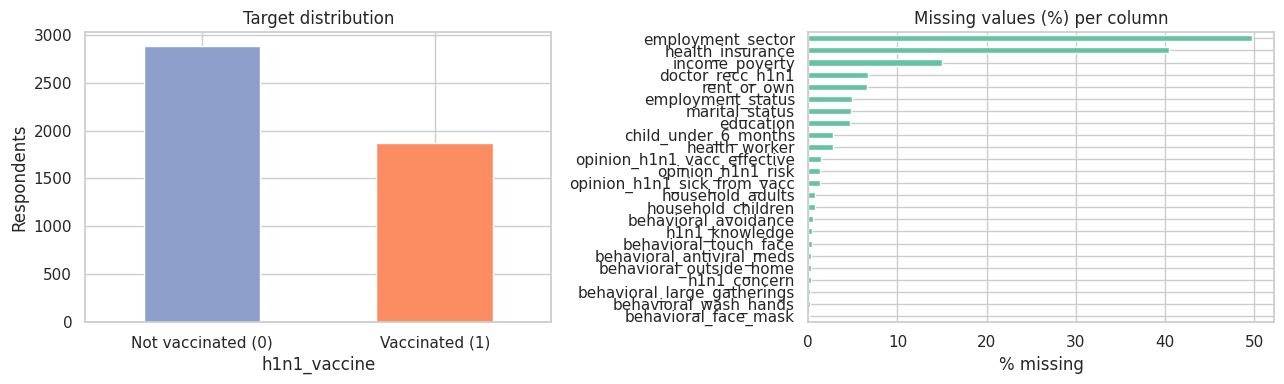

In [5]:
# 4a. Target balance and missing values side by side
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
train[TARGET].value_counts().sort_index().plot(kind="bar", ax=axes[0], color=["#8da0cb", "#fc8d62"])
axes[0].set_xticklabels(["Not vaccinated (0)", "Vaccinated (1)"], rotation=0)
axes[0].set_title("Target distribution"); axes[0].set_ylabel("Respondents")

mp = (train.drop(columns=[ID, TARGET]).isna().mean() * 100)
mp = mp[mp > 0].sort_values()
mp.plot(kind="barh", ax=axes[1], color="#66c2a5")
axes[1].set_title("Missing values (%) per column"); axes[1].set_xlabel("% missing")
plt.tight_layout(); plt.show()

In [6]:
# 4b. Is missingness itself informative? (vaccination rate when a value is missing vs present)
rows = []
for c in mp.sort_values(ascending=False).index[:6]:
    rows.append({"column": c,
                 "vaccinated rate when MISSING": train.loc[train[c].isna(), TARGET].mean(),
                 "vaccinated rate when present": train.loc[train[c].notna(), TARGET].mean()})
display(pd.DataFrame(rows).round(3))

,column,vaccinated rate when MISSING,vaccinated rate when present
0,employment_sector,0.385,0.403
1,health_insurance,0.236,0.502
2,income_poverty,0.365,0.399
3,doctor_recc_h1n1,0.182,0.409
4,rent_or_own,0.352,0.397
5,employment_status,0.353,0.396


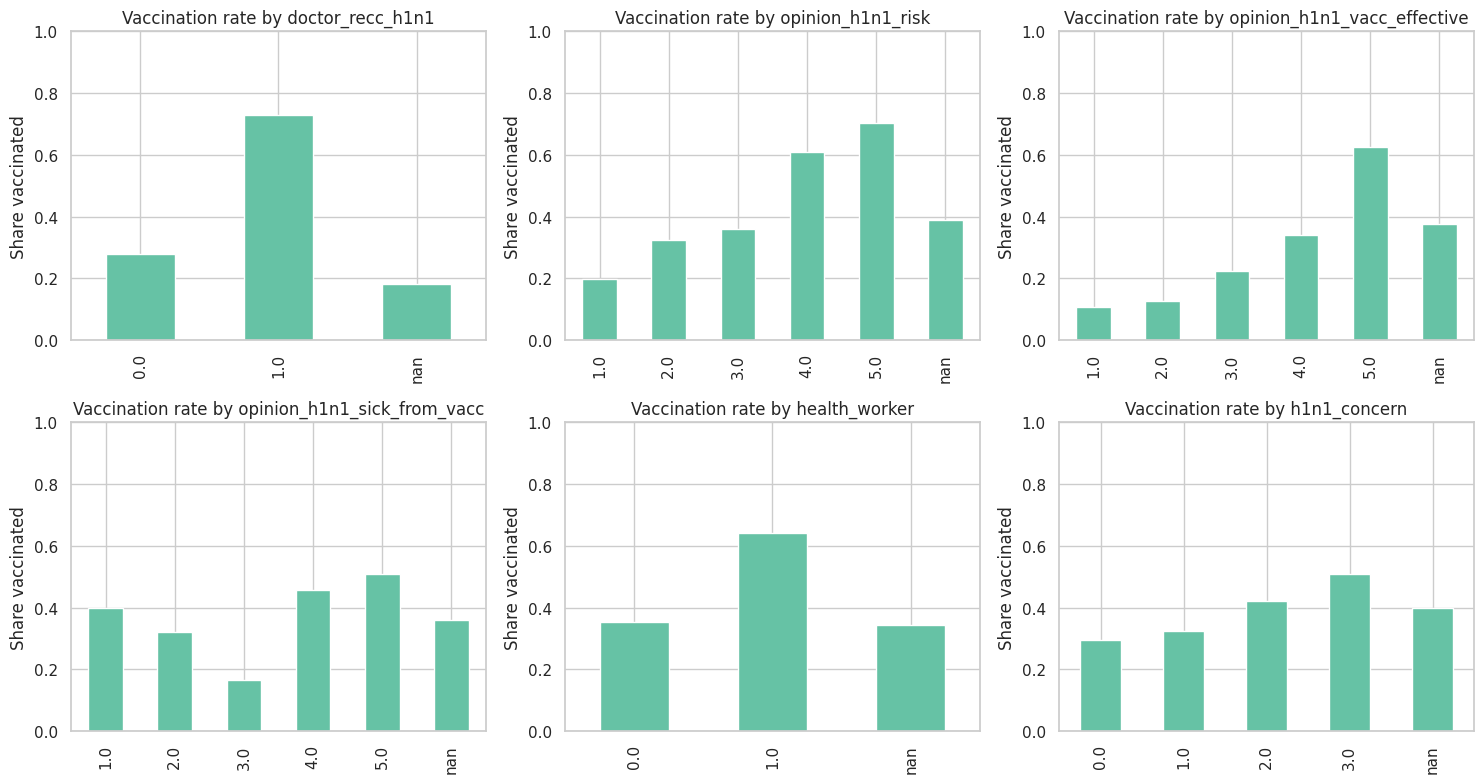

In [7]:
# 4c. Vaccination rate by the opinion / behaviour / medical features
plot_cols = ["doctor_recc_h1n1", "opinion_h1n1_risk", "opinion_h1n1_vacc_effective",
             "opinion_h1n1_sick_from_vacc", "health_worker", "h1n1_concern"]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.ravel(), plot_cols):
    rate = train.groupby(col, dropna=False)[TARGET].mean().sort_index()
    rate.plot(kind="bar", ax=ax, color="#66c2a5")
    ax.set_title(f"Vaccination rate by {col}")
    ax.set_ylabel("Share vaccinated"); ax.set_xlabel(""); ax.set_ylim(0, 1)
plt.tight_layout(); plt.show()

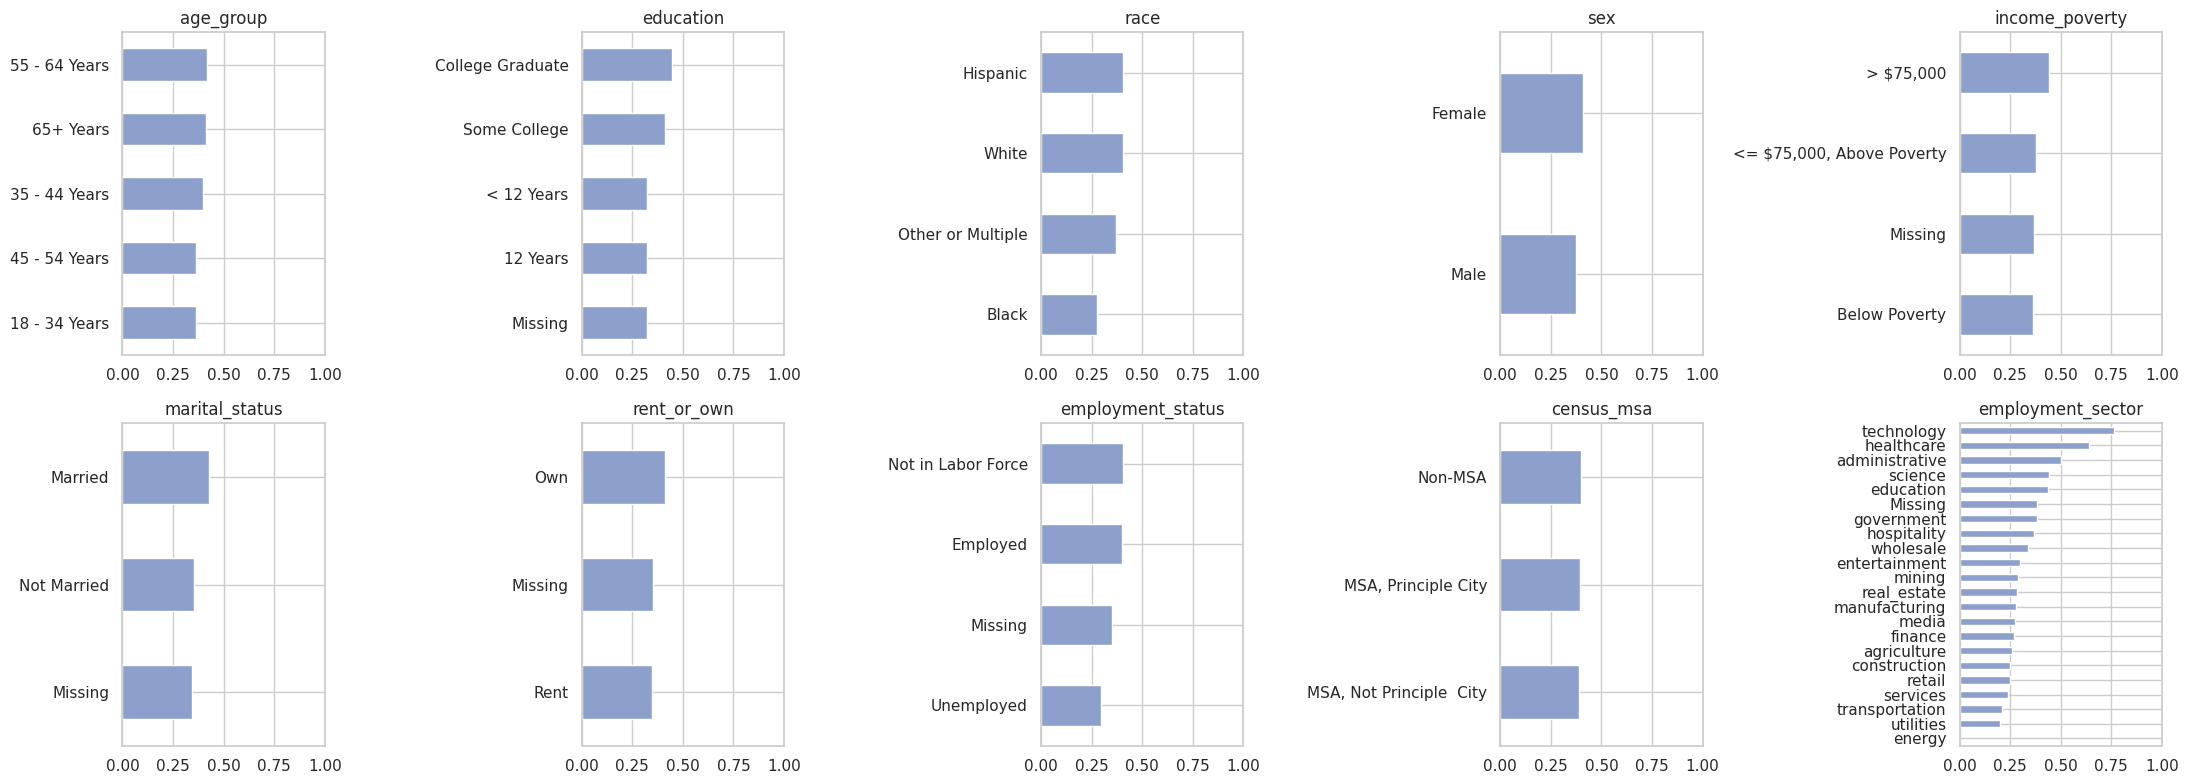

In [8]:
# 4d. Vaccination rate by every categorical (text) feature
cat_eda = [c for c in train.columns if c not in (ID, TARGET) and not pd.api.types.is_numeric_dtype(train[c])]
fig, axes = plt.subplots(2, 5, figsize=(22, 8))
for ax, col in zip(axes.ravel(), cat_eda):
    rate = train.groupby(train[col].fillna("Missing"))[TARGET].mean().sort_values()
    rate.plot(kind="barh", ax=ax, color="#8da0cb")
    ax.set_title(col); ax.set_ylabel(""); ax.set_xlim(0, 1)
plt.tight_layout(); plt.show()

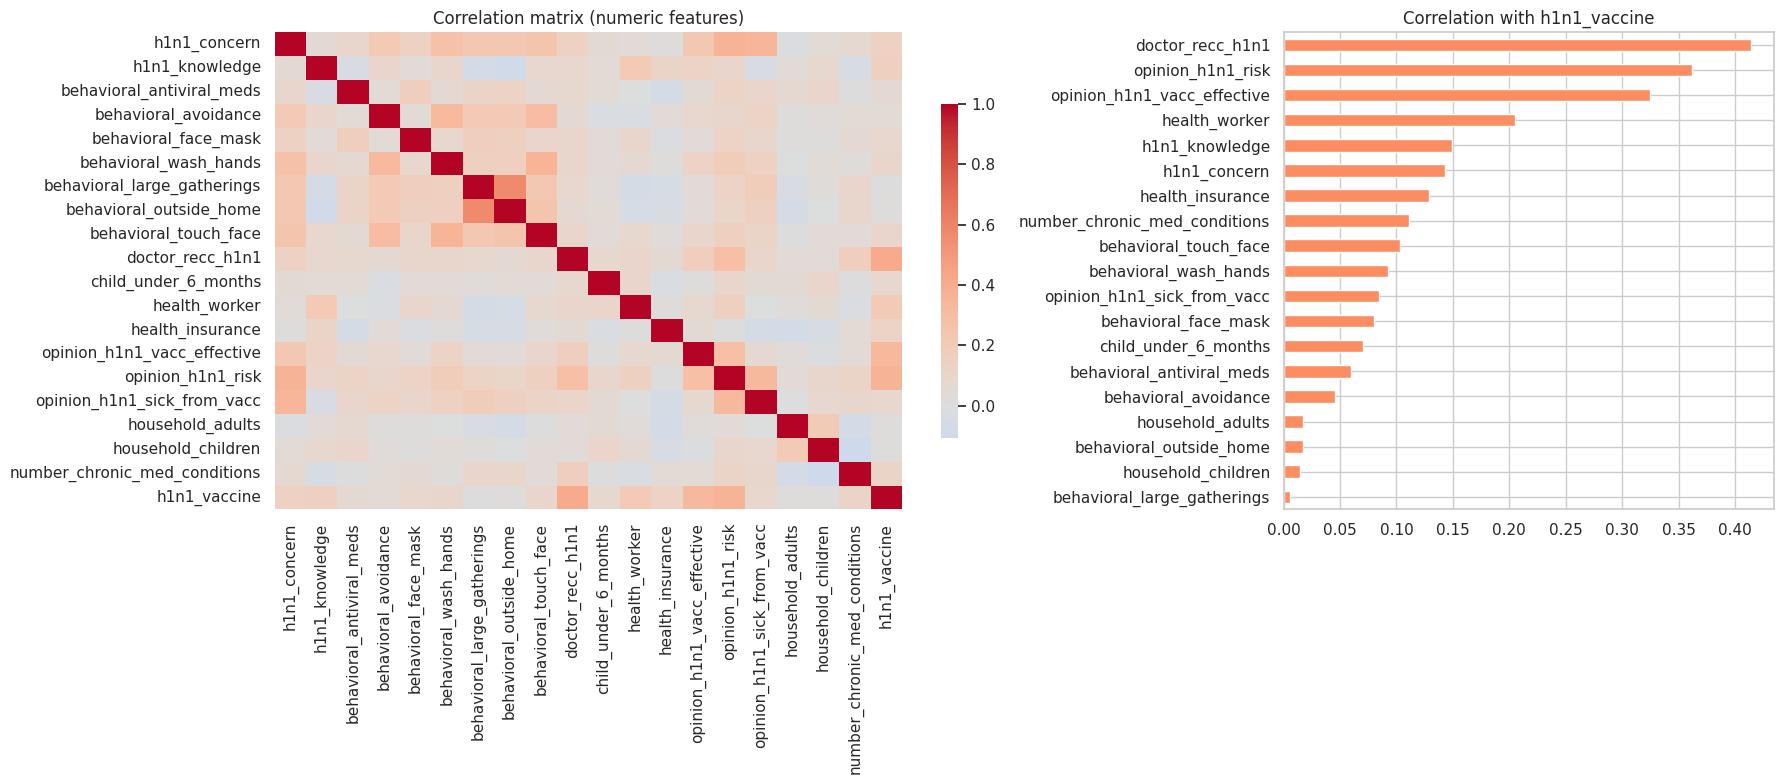

In [9]:
# 4e. Correlation of numeric features with each other and with the target
num_eda = train.select_dtypes(include="number").drop(columns=[ID])
fig, axes = plt.subplots(1, 2, figsize=(18, 8), gridspec_kw={"width_ratios": [1.6, 1]})
sns.heatmap(num_eda.corr(), cmap="coolwarm", center=0, ax=axes[0], cbar_kws={"shrink": 0.7})
axes[0].set_title("Correlation matrix (numeric features)")
corr = num_eda.corr()[TARGET].drop(TARGET).sort_values()
corr.plot(kind="barh", ax=axes[1], color="#fc8d62")
axes[1].set_title("Correlation with h1n1_vaccine")
plt.tight_layout(); plt.show()

**What the EDA tells us (use this on your EDA slide):**
- About 39% accept the vaccine, so classes are mildly imbalanced.
- `employment_sector` and `health_insurance` have very high missingness, so we test dropping them versus keeping a "Missing" category (Step 8).
- A doctor's recommendation and the opinions about risk and vaccine effectiveness are the strongest signals.
- Demographics matter less; the opinion and behaviour features carry most of the information.

## Step 5: Prepare columns
Real missing values are **kept as missing** here. All imputation happens *inside* the modelling pipelines, so each cross-validation fold
learns its imputation only from its own training part (no data leakage).

In [10]:
feature_cols = [c for c in train.columns if c not in (ID, TARGET)]
cat_cols = [c for c in feature_cols if not pd.api.types.is_numeric_dtype(train[c])]
num_cols = [c for c in feature_cols if pd.api.types.is_numeric_dtype(train[c])]
HIGH_MISSING = [c for c in feature_cols if train[c].isna().mean() > 0.40]

# use plain Python objects with np.nan for missing text values (what scikit-learn imputers expect)
for df in (train, test):
    for c in cat_cols:
        df[c] = df[c].astype(object).where(df[c].notna(), np.nan)

X = train[feature_cols].copy()
y = train[TARGET].astype(int)
X_test = test[feature_cols].copy()
y_arr = y.values

print(f"{len(num_cols)} numeric columns, {len(cat_cols)} categorical columns")
print("Columns with more than 40% missing:", HIGH_MISSING)
print("X:", X.shape, "| y:", y.shape, "| X_test:", X_test.shape)

19 numeric columns, 10 categorical columns
Columns with more than 40% missing: ['health_insurance', 'employment_sector']
X: (4756, 29) | y: (4756,) | X_test: (4749, 29)


## Step 6: Hospitalisation probabilities (generative-AI estimates)
The brief says the evaluation metric is **not given as a formula**. We must work it out and estimate hospitalisation probabilities, using
generative AI for this part, and ask **different AIs (or different people)** to check robustness.

For each person we need:
- `p_u` = probability of hospitalisation if **unvaccinated**
- `p_v` = probability of hospitalisation if **vaccinated** = `p_u x (1 - vaccine effectiveness)`

Everyone is infected (100%), so `p_u` is the chance of being hospitalised once infected. We use two features from the dataset:
**age group** and **number of chronic conditions**.

**How to use this step**
1. Ask 2 or 3 different AIs (Gemini, ChatGPT, Claude...) the prompt below, ideally by different teammates.
2. Paste each answer into `AI_ESTIMATES` (a commented template is included). The notebook averages them into a **consensus**.
3. Step 12 checks how sensitive the final ranking is to these numbers.

**Prompt to give each AI:**
> *A town of adults (18+) is hit by an H1N1 flu outbreak and everyone is infected (100%). For each age group (18-34, 35-44, 45-54, 55-64, 65+),
> what is the probability that an infected, UNVACCINATED person is hospitalised? By what factor does that probability multiply for people with
> 1 and with 2 or more chronic medical conditions (asthma/lung, diabetes, heart, kidney, anaemia, neurological, liver, weakened immune system)?
> And how effective is the H1N1 vaccine at preventing hospitalisation (percentage reduction)? Give numbers and sources.*

The first entry was produced by Claude and anchored on public data: CDC's 2009 pandemic estimates imply roughly **0.45%** of cases were hospitalised overall
(about 213,000 hospitalisations for about 47 million cases at the mid-level estimates to Nov 2009), with higher risk in older adults; a US case-control study found one
H1N1 vaccine dose was about **50%** effective (95% CI 13% to 71%) against hospitalisation, and CDC modelling assumed **62%** (43% for 65+).
These are estimates, not facts about your town. **Add your own AI answers and record which AIs you used in your write-up.**

In [11]:
AGE_ORDER = ["18 - 34 Years", "35 - 44 Years", "45 - 54 Years", "55 - 64 Years", "65+ Years"]

AI_ESTIMATES = {
    "Claude (anchored on CDC 2009 H1N1 data)": {
        # probability of hospitalisation if infected AND unvaccinated, by age group
        "base_hosp_prob_unvaccinated": {
            "18 - 34 Years": 0.004, "35 - 44 Years": 0.005, "45 - 54 Years": 0.007,
            "55 - 64 Years": 0.010, "65+ Years": 0.015},
        # multiplier by number of chronic conditions (2 means "2 or more")
        "chronic_multiplier": {0: 1.0, 1: 2.0, 2: 3.0},
        # percentage reduction in hospitalisation risk from vaccination (0.55 = 55%)
        "vaccine_effectiveness": 0.55,
    },
    # ---- Template: paste your other AI answers here (remove the leading # on each line) ----
    # "Gemini": {
    #     "base_hosp_prob_unvaccinated": {"18 - 34 Years": 0.003, "35 - 44 Years": 0.004,
    #         "45 - 54 Years": 0.006, "55 - 64 Years": 0.009, "65+ Years": 0.020},
    #     "chronic_multiplier": {0: 1.0, 1: 2.0, 2: 4.0},
    #     "vaccine_effectiveness": 0.60,
    # },
}

def consensus_params(estimates):
    """Average the AI answers into one consensus set of parameters."""
    base = pd.DataFrame({k: v["base_hosp_prob_unvaccinated"] for k, v in estimates.items()}).mean(axis=1).to_dict()
    mult = pd.DataFrame({k: v["chronic_multiplier"] for k, v in estimates.items()}).mean(axis=1).to_dict()
    ve = float(np.mean([v["vaccine_effectiveness"] for v in estimates.values()]))
    return base, mult, ve

BASE, MULT, VE = consensus_params(AI_ESTIMATES)

def hosp_probs(df, base, mult, ve, base_scale=1.0):
    """Return (p_unvaccinated, p_vaccinated) for every row of df."""
    p_u = df["age_group"].map(base).astype(float).fillna(float(np.mean(list(base.values()))))
    chronic = df["number_chronic_med_conditions"].fillna(0).clip(lower=0, upper=2).astype(int)
    p_u = (p_u * chronic.map(mult).astype(float) * base_scale).clip(upper=1.0)
    return p_u.values, (p_u * (1 - ve)).values

p_u_train, p_v_train = hosp_probs(train, BASE, MULT, VE)
p_u_test, p_v_test = hosp_probs(test, BASE, MULT, VE)

print(f"AI sources used: {len(AI_ESTIMATES)} -> {list(AI_ESTIMATES)}")
if len(AI_ESTIMATES) < 2:
    print("WARNING: the brief asks you to check several AIs. Add at least one more source above.")
print(f"Consensus vaccine effectiveness: {VE:.0%}")
print(f"Average hospitalisation probability if unvaccinated: {p_u_train.mean():.2%}")
print(f"Average hospitalisation probability if vaccinated:   {p_v_train.mean():.2%}")
display((pd.DataFrame({"age_group": train["age_group"], "p_unvaccinated": p_u_train})
         .groupby("age_group")["p_unvaccinated"].mean().reindex(AGE_ORDER)
         .map("{:.2%}".format).to_frame()))

AI sources used: 1 -> ['Claude (anchored on CDC 2009 H1N1 data)']
Consensus vaccine effectiveness: 55%
Average hospitalisation probability if unvaccinated: 1.27%
Average hospitalisation probability if vaccinated:   0.57%


,p_unvaccinated
age_group,
18 - 34 Years,0.49%
35 - 44 Years,0.62%
45 - 54 Years,0.92%
55 - 64 Years,1.44%
65+ Years,2.30%


## Step 7: The evaluation metric: the town's total cost
**Why not accuracy or F1?** The brief asks us to minimise the *money* the town spends, and a mistake does not always cost the same.
We rebuilt the metric from the rules in the brief:

- Everyone is infected, so every person can be hospitalised (probability `p_u` if unvaccinated, `p_v` if vaccinated).
- Everyone who **wants** a vaccine (true label 1) must get one. If we do not send one, the town **pays them $500 instead**, so that $500 is spent either way.
- Vaccines are posted to homes and **wasted if not used**. A vaccine sent to someone who will not accept it (true label 0) costs $500 and that person stays unvaccinated.

**Assumption to confirm with your tutor:** a person who wants a vaccine but is only paid $500 is treated as **unvaccinated** for hospitalisation.

| Our prediction | Truth | Vaccine spend | Hospitalisation risk |
|---|---|---|---|
| 1 (send vaccine) | 1 (wants it) | $500 | `p_v` |
| 1 (send vaccine) | 0 (will not use it) | $500 (wasted) | `p_u` |
| 0 (do not send) | 1 (wants it) | $500 (paid cash instead) | `p_u` |
| 0 (do not send) | 0 | $0 | `p_u` |

**Total cost = vaccine spend + $25,000 x expected number hospitalised.**

**Best decision per person:** with `P` = probability the person accepts, send a vaccine when
`P x 25,000 x (p_u - p_v) > (1 - P) x 500`, i.e. when `P > 500 / (500 + 25,000 x (p_u - p_v))`.
High-risk people get a lower threshold, low-risk people a higher one. Because this rule uses `P` directly, **well-calibrated probabilities matter**
(so we tune models with log-loss in Step 10).

In [12]:
COST_VACCINE = 500
COST_HOSPITAL = 25000

def town_cost(pred, y_true, p_u, p_v):
    """Total cost to the town. Returns (total, vaccine_spend, hospitalisation_cost)."""
    pred = np.asarray(pred).astype(int)
    truth = np.asarray(y_true).astype(int)
    # $500 is spent if we send a vaccine OR the person wanted one (then we pay them cash)
    vaccine_spend = COST_VACCINE * ((pred == 1) | (truth == 1)).sum()
    # only people who were sent a vaccine AND will use it are protected
    protected = (pred == 1) & (truth == 1)
    hosp_cost = COST_HOSPITAL * np.where(protected, p_v, p_u).sum()
    return vaccine_spend + hosp_cost, vaccine_spend, hosp_cost

def person_threshold(p_u, p_v):
    """Per-person probability above which sending a vaccine lowers the expected cost."""
    delta = np.maximum(p_u - p_v, 1e-12)
    return COST_VACCINE / (COST_VACCINE + COST_HOSPITAL * delta)

# Reference points for the whole training town
refs = {}
for label, pred in [("Flag nobody (pay everyone who wants one)", np.zeros(len(y_arr))),
                    ("Flag everybody", np.ones(len(y_arr))),
                    ("Perfect predictions (lower bound)", y_arr)]:
    tot, vs, hc = town_cost(pred, y_arr, p_u_train, p_v_train)
    refs[label] = tot / len(y_arr)
    print(f"{label:42s} total ${tot:>12,.0f} | vaccines ${vs:>10,.0f} | hospital ${hc:>12,.0f} | per person ${tot/len(y_arr):,.2f}")
COST_NOBODY = refs["Flag nobody (pay everyone who wants one)"]
COST_PERFECT = refs["Perfect predictions (lower bound)"]

Flag nobody (pay everyone who wants one)   total $   2,448,125 | vaccines $   937,000 | hospital $   1,511,125 | per person $514.74
Flag everybody                             total $   3,534,952 | vaccines $ 2,378,000 | hospital $   1,156,952 | per person $743.26
Perfect predictions (lower bound)          total $   2,093,952 | vaccines $   937,000 | hospital $   1,156,952 | per person $440.28


## Step 8: Compare pre-processing options
We test five ways of handling missing values and encoding categories, using two different models (a linear one and a boosted-tree one).
Every number comes from **5-fold cross-validation**, which also shows the random variation (the ± values).
The cost uses the person-specific rule from Step 7.

In [13]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

# fold number of every row (lets us compute the cost spread across folds for any set of predictions)
fold_id = np.zeros(len(y), dtype=int)
for k, (_, va) in enumerate(cv.split(X, y)):
    fold_id[va] = k

def cv_evaluate(pipe, X, y):
    """5-fold CV. Returns fold AUCs, fold costs per person (person-specific rule) and out-of-fold probabilities."""
    oof = np.zeros(len(y))
    aucs, costs = [], []
    for tr_idx, va_idx in cv.split(X, y):
        model = clone(pipe).fit(X.iloc[tr_idx], y.iloc[tr_idx])
        proba = model.predict_proba(X.iloc[va_idx])[:, 1]
        oof[va_idx] = proba
        truth = y.iloc[va_idx].values
        pred = (proba > person_threshold(p_u_train[va_idx], p_v_train[va_idx])).astype(int)
        aucs.append(roc_auc_score(truth, proba))
        costs.append(town_cost(pred, truth, p_u_train[va_idx], p_v_train[va_idx])[0] / len(va_idx))
    return {"auc": np.array(aucs), "cost": np.array(costs), "oof": oof}

ORDERED = {  # categories that have a natural order
    "age_group": AGE_ORDER,
    "education": ["< 12 Years", "12 Years", "Some College", "College Graduate"],
    "income_poverty": ["Below Poverty", "<= $75,000, Above Poverty", "> $75,000"],
}

PREP_OPTIONS = {
    "baseline": "median for numbers + 'Missing' category + one-hot",
    "missing_flags": "baseline + extra 'was missing' flag columns",
    "mode_impute": "most-frequent value for text columns + one-hot",
    "drop_high_missing": "baseline, dropping columns with >40% missing",
    "ordinal_encode": "ordered categories as numbers + one-hot for the rest",
}

def make_preprocessor(option="baseline", scale=False):
    """Build a ColumnTransformer for one of the pre-processing options above."""
    drop = HIGH_MISSING if option == "drop_high_missing" else []
    nums = [c for c in num_cols if c not in drop]
    cats = [c for c in cat_cols if c not in drop]

    num_steps = [("imputer", SimpleImputer(strategy="median", add_indicator=(option == "missing_flags")))]
    if scale:
        num_steps.append(("scaler", StandardScaler()))
    parts = [("num", Pipeline(num_steps), nums)]

    if option == "ordinal_encode":
        ord_cols = [c for c in ORDERED if c in cats]
        cats = [c for c in cats if c not in ord_cols]
        ord_steps = [("imputer", SimpleImputer(strategy="constant", fill_value="Missing")),
                     ("encoder", OrdinalEncoder(categories=[ORDERED[c] for c in ord_cols],
                                                handle_unknown="use_encoded_value", unknown_value=-1))]
        if scale:
            ord_steps.append(("scaler", StandardScaler()))
        parts.append(("ord", Pipeline(ord_steps), ord_cols))

    if option == "mode_impute":
        cat_imp = SimpleImputer(strategy="most_frequent")
    else:
        cat_imp = SimpleImputer(strategy="constant", fill_value="Missing")
    parts.append(("cat", Pipeline([("imputer", cat_imp),
                                   ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]), cats))
    return ColumnTransformer(parts)

rows = []
for opt, desc in PREP_OPTIONS.items():
    lr = Pipeline([("prep", make_preprocessor(opt, scale=True)),
                   ("model", LogisticRegression(max_iter=3000, random_state=RANDOM_STATE))])
    gb = Pipeline([("prep", make_preprocessor(opt)),
                   ("model", HistGradientBoostingClassifier(random_state=RANDOM_STATE))])
    r_lr, r_gb = cv_evaluate(lr, X, y), cv_evaluate(gb, X, y)
    rows.append({"option": opt, "description": desc,
                 "LR AUC": r_lr["auc"].mean(), "LR cost/person": r_lr["cost"].mean(),
                 "GB AUC": r_gb["auc"].mean(), "GB cost/person": r_gb["cost"].mean(),
                 "avg cost/person": (r_lr["cost"].mean() + r_gb["cost"].mean()) / 2})

prep_table = pd.DataFrame(rows).sort_values("avg cost/person").reset_index(drop=True)
display(prep_table.round(4))

BEST_PREP = prep_table.loc[0, "option"]    # you may override this, e.g. BEST_PREP = "baseline"
print(f"\nChosen pre-processing: {BEST_PREP}  ({PREP_OPTIONS[BEST_PREP]})")
gb_auc, gb_cost = prep_table["GB AUC"], prep_table["GB cost/person"]
print(f"Across options (boosted trees): AUC {gb_auc.min():.3f} to {gb_auc.max():.3f}; "
      f"cost ${gb_cost.min():.1f} to ${gb_cost.max():.1f} per person.")
print("Compare these gaps with the fold-to-fold spread (roughly +/-0.01 AUC and +/-$10 per person, see Step 9) "
      "before claiming one option is clearly better.")

,option,description,LR AUC,LR cost/person,GB AUC,GB cost/person,avg cost/person
0,missing_flags,baseline + extra 'was missing' flag columns,0.8488,488.5900,0.8491,486.7125,487.6512
1,baseline,median for numbers + 'Missing' category + one-hot,0.8230,491.7628,0.8236,490.0476,490.9052
2,ordinal_encode,ordered categories as numbers + one-hot for th...,0.8237,491.7019,0.8238,490.7731,491.2375
3,drop_high_missing,"baseline, dropping columns with >40% missing",0.8204,491.6179,0.8186,492.1414,491.8796
4,mode_impute,most-frequent value for text columns + one-hot,0.8229,492.2071,0.8213,491.9249,492.0660



Chosen pre-processing: missing_flags  (baseline + extra 'was missing' flag columns)
Across options (boosted trees): AUC 0.819 to 0.849; cost $486.7 to $492.1 per person.
Compare these gaps with the fold-to-fold spread (roughly +/-0.01 AUC and +/-$10 per person, see Step 9) before claiming one option is clearly better.


## Step 9: Compare different models (5-fold cross-validation)
We compare many different model families on the **same folds** and the **same metric**: linear, a single tree, distance-based, bagged trees,
boosted trees and a small neural network (plus XGBoost and LightGBM when installed). The ± values are the standard deviation across folds,
which measures the size of random variation.

Models that give poorly calibrated probabilities (single trees, K-nearest neighbours) are expected to do worse on cost, because the cost rule depends on
the probability itself and not only on the ranking of people.

,model,AUC,AUC ±,log-loss,cost/person ($),cost ±,share flagged
1,Gradient Boosting (HistGB),0.8491,0.0115,0.4685,486.7125,11.4740,0.2037
2,XGBoost,0.8542,0.0096,0.4573,487.0368,11.4490,0.1871
3,LightGBM,0.8524,0.0097,0.4611,487.5178,12.4381,0.2052
4,Logistic Regression,0.8488,0.0091,0.4660,488.5900,10.2577,0.1884
5,Neural Network (MLP),0.8462,0.0115,0.4715,488.9298,9.5467,0.2044
6,Extra Trees,0.8477,0.0068,0.4829,489.8862,10.2488,0.1146
7,Random Forest,0.8524,0.0112,0.4789,490.5581,9.9572,0.1125
8,Decision Tree,0.8208,0.0094,0.5064,492.1008,8.8479,0.1722
9,K-Nearest Neighbours,0.8303,0.0116,0.5031,493.8024,10.7323,0.0969


Reference per person: flag nobody $514.74 | perfect predictions $440.28


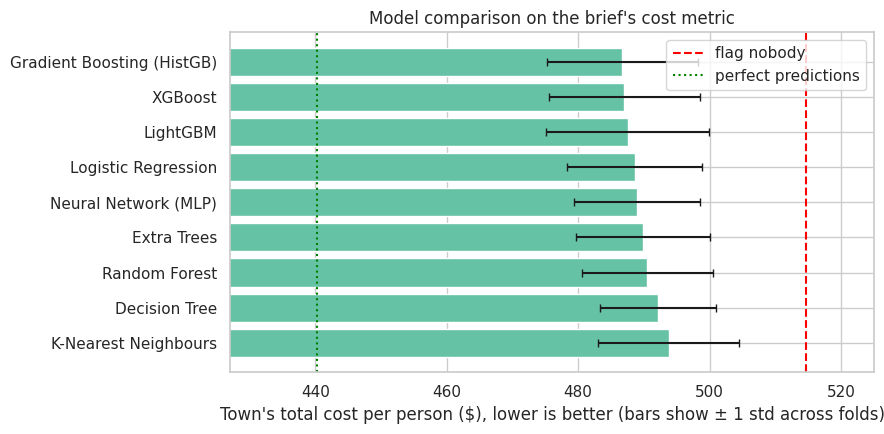

In [14]:
def build_models(prep):
    """All models we compare, each inside a pipeline with the chosen pre-processing."""
    rs = RANDOM_STATE
    models = {
        "Logistic Regression": Pipeline([("prep", make_preprocessor(prep, scale=True)),
            ("model", LogisticRegression(max_iter=3000, random_state=rs))]),
        "Decision Tree": Pipeline([("prep", make_preprocessor(prep)),
            ("model", DecisionTreeClassifier(max_depth=5, min_samples_leaf=30, random_state=rs))]),
        "K-Nearest Neighbours": Pipeline([("prep", make_preprocessor(prep, scale=True)),
            ("model", KNeighborsClassifier(n_neighbors=50))]),
        "Random Forest": Pipeline([("prep", make_preprocessor(prep)),
            ("model", RandomForestClassifier(n_estimators=300, min_samples_leaf=3, n_jobs=-1, random_state=rs))]),
        "Extra Trees": Pipeline([("prep", make_preprocessor(prep)),
            ("model", ExtraTreesClassifier(n_estimators=300, min_samples_leaf=3, n_jobs=-1, random_state=rs))]),
        "Gradient Boosting (HistGB)": Pipeline([("prep", make_preprocessor(prep)),
            ("model", HistGradientBoostingClassifier(random_state=rs))]),
        "Neural Network (MLP)": Pipeline([("prep", make_preprocessor(prep, scale=True)),
            ("model", MLPClassifier(hidden_layer_sizes=(64, 32), alpha=1e-3, early_stopping=True,
                                    max_iter=300, random_state=rs))]),
    }
    if XGBClassifier is not None:
        models["XGBoost"] = Pipeline([("prep", make_preprocessor(prep)),
            ("model", XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=3, subsample=0.8,
                                    colsample_bytree=0.8, eval_metric="logloss", random_state=rs, n_jobs=-1))])
    if LGBMClassifier is not None:
        models["LightGBM"] = Pipeline([("prep", make_preprocessor(prep)),
            ("model", LGBMClassifier(n_estimators=300, learning_rate=0.05, num_leaves=15, subsample=0.8,
                                     subsample_freq=1, colsample_bytree=0.8, random_state=rs, n_jobs=-1, verbose=-1))])
    return models

baseline_models = build_models(BEST_PREP)
baseline_results = {}
rows = []
for name, pipe in baseline_models.items():
    res = cv_evaluate(pipe, X, y)
    baseline_results[name] = res
    rows.append({"model": name,
                 "AUC": res["auc"].mean(), "AUC ±": res["auc"].std(),
                 "log-loss": log_loss(y, np.clip(res["oof"], 1e-6, 1 - 1e-6)),
                 "cost/person ($)": res["cost"].mean(), "cost ±": res["cost"].std(),
                 "share flagged": (res["oof"] > person_threshold(p_u_train, p_v_train)).mean()})

model_table = pd.DataFrame(rows).sort_values("cost/person ($)").reset_index(drop=True)
model_table.index = model_table.index + 1
display(model_table.round(4))
print(f"Reference per person: flag nobody ${COST_NOBODY:,.2f} | perfect predictions ${COST_PERFECT:,.2f}")

fig, ax = plt.subplots(figsize=(9, 4.5))
mt = model_table.iloc[::-1]
ax.barh(mt["model"], mt["cost/person ($)"], xerr=mt["cost ±"], color="#66c2a5", capsize=3)
ax.axvline(COST_NOBODY, color="red", linestyle="--", label="flag nobody")
ax.axvline(COST_PERFECT, color="green", linestyle=":", label="perfect predictions")
lo = min(COST_PERFECT, mt["cost/person ($)"].min()) * 0.97
ax.set_xlim(lo, max(COST_NOBODY, mt["cost/person ($)"].max()) * 1.02)
ax.set_xlabel("Town's total cost per person ($), lower is better (bars show ± 1 std across folds)")
ax.set_title("Model comparison on the brief's cost metric"); ax.legend()
plt.tight_layout(); plt.show()

## Step 10: Hyper-parameter tuning and hold-out validation
- The data is split 80/20 (stratified). **Tuning uses only the 80% part**; the 20% hold-out is data the models never saw, so it gives an honest result.
- We tune the three most useful model families: gradient boosting, random forest and logistic regression.
- Tuning criterion: **log-loss** (it rewards well-calibrated probabilities, which the per-person cost rule relies on).

In [15]:
idx_tr, idx_val = train_test_split(np.arange(len(X)), test_size=0.2, stratify=y, random_state=RANDOM_STATE)
X_train, X_val = X.iloc[idx_tr], X.iloc[idx_val]
y_train, y_val = y.iloc[idx_tr], y.iloc[idx_val]

search_spaces = {
    "Gradient Boosting (HistGB)": (
        Pipeline([("prep", make_preprocessor(BEST_PREP)),
                  ("model", HistGradientBoostingClassifier(random_state=RANDOM_STATE))]),
        {"model__learning_rate": [0.01, 0.03, 0.05, 0.1],
         "model__max_iter": [100, 200, 300, 500],
         "model__max_depth": [None, 3, 5, 7],
         "model__min_samples_leaf": [10, 20, 40, 80],
         "model__l2_regularization": [0.0, 0.1, 1.0, 5.0]}, 20),
    "Random Forest": (
        Pipeline([("prep", make_preprocessor(BEST_PREP)),
                  ("model", RandomForestClassifier(n_jobs=-1, random_state=RANDOM_STATE))]),
        {"model__n_estimators": [200, 300, 500],
         "model__max_depth": [None, 6, 10, 15],
         "model__min_samples_leaf": [3, 5, 10, 20],
         "model__max_features": ["sqrt", 0.3, 0.5]}, 15),
    "Logistic Regression": (
        Pipeline([("prep", make_preprocessor(BEST_PREP, scale=True)),
                  ("model", LogisticRegression(max_iter=3000, random_state=RANDOM_STATE))]),
        {"model__C": [0.003, 0.01, 0.03, 0.1, 0.3, 1.0, 3.0]}, None),
}

searches = {}
for name, (pipe, grid, n_iter) in search_spaces.items():
    if n_iter is None:
        s = GridSearchCV(pipe, grid, scoring="neg_log_loss", cv=cv, n_jobs=-1)
    else:
        s = RandomizedSearchCV(pipe, grid, n_iter=n_iter, scoring="neg_log_loss", cv=cv,
                               random_state=RANDOM_STATE, n_jobs=-1)
    s.fit(X_train, y_train)
    searches[name] = s
    print(f"{name}: best CV log-loss {-s.best_score_:.4f} | {s.best_params_}")

Gradient Boosting (HistGB): best CV log-loss 0.4534 | {'model__min_samples_leaf': 20, 'model__max_iter': 500, 'model__max_depth': None, 'model__learning_rate': 0.01, 'model__l2_regularization': 1.0}
Random Forest: best CV log-loss 0.4568 | {'model__n_estimators': 300, 'model__min_samples_leaf': 5, 'model__max_features': 0.5, 'model__max_depth': 10}
Logistic Regression: best CV log-loss 0.4634 | {'model__C': 0.03}


In [16]:
# Hold-out validation: default vs tuned version of each model
def holdout_row(name, model, label):
    proba = model.predict_proba(X_val)[:, 1]
    pred = (proba > person_threshold(p_u_train[idx_val], p_v_train[idx_val])).astype(int)
    tot = town_cost(pred, y_val.values, p_u_train[idx_val], p_v_train[idx_val])[0] / len(idx_val)
    return {"model": name, "version": label, "AUC": roc_auc_score(y_val, proba),
            "log-loss": log_loss(y_val, np.clip(proba, 1e-6, 1 - 1e-6)), "cost/person ($)": tot}

rows = []
for name, s in searches.items():
    default_model = clone(baseline_models[name]).fit(X_train, y_train)
    rows.append(holdout_row(name, default_model, "default"))
    rows.append(holdout_row(name, s.best_estimator_, "tuned"))

holdout_table = pd.DataFrame(rows)
display(holdout_table.round(4))

hv = np.zeros(len(idx_val))
nobody_hold = town_cost(hv, y_val.values, p_u_train[idx_val], p_v_train[idx_val])[0] / len(idx_val)
perfect_hold = town_cost(y_val.values, y_val.values, p_u_train[idx_val], p_v_train[idx_val])[0] / len(idx_val)
print(f"Hold-out reference: flag nobody ${nobody_hold:,.2f} | perfect ${perfect_hold:,.2f} per person")

,model,version,AUC,log-loss,cost/person ($)
0,Gradient Boosting (HistGB),default,0.8343,0.4923,495.6723
1,Gradient Boosting (HistGB),tuned,0.8403,0.4772,494.1859
2,Random Forest,default,0.8335,0.4962,495.6145
3,Random Forest,tuned,0.8297,0.4916,492.7245
4,Logistic Regression,default,0.8380,0.4814,493.4388
5,Logistic Regression,tuned,0.8380,0.4801,495.0079


Hold-out reference: flag nobody $521.03 | perfect $442.88 per person


## Step 11: Build candidate submissions and rank them by total cost
Each tuned model is refitted with cross-validation on **all** the labelled data, giving an honest out-of-fold probability for every person.
We then apply different decision rules and score the town's total cost. We also report the **spread across folds (±)**, so you can see which
differences are real and which are just random variation. A neural network is added as a different kind of model, and an **ensemble** averages them.

In [17]:
final_models = {name: clone(s.best_estimator_) for name, s in searches.items()}
final_models["Neural Network (MLP)"] = clone(baseline_models["Neural Network (MLP)"])

oof_proba, test_proba = {}, {}
for name, pipe in final_models.items():
    oof_proba[name] = cv_evaluate(pipe, X, y)["oof"]          # honest out-of-fold probabilities
    test_proba[name] = clone(pipe).fit(X, y).predict_proba(X_test)[:, 1]
    print(f"{name:28s} out-of-fold AUC = {roc_auc_score(y, oof_proba[name]):.4f}")

oof_proba["Ensemble (average)"] = np.mean([oof_proba[m] for m in final_models], axis=0)
test_proba["Ensemble (average)"] = np.mean([test_proba[m] for m in final_models], axis=0)
print(f"{'Ensemble (average)':28s} out-of-fold AUC = {roc_auc_score(y, oof_proba['Ensemble (average)']):.4f}")

Gradient Boosting (HistGB)   out-of-fold AUC = 0.8533
Random Forest                out-of-fold AUC = 0.8496
Logistic Regression          out-of-fold AUC = 0.8494
Neural Network (MLP)         out-of-fold AUC = 0.8458
Ensemble (average)           out-of-fold AUC = 0.8568


Best single global threshold for the ensemble: 0.74
Person-specific thresholds range from 0.45 to 0.90


,candidate,cost per person ($),± across folds,saving vs flag-nobody ($/person),"est. total cost, test town ($)",share flagged (train),share flagged (test),accuracy
rank,,,,,,,,
1,Ensemble (average) + person-specific cost rule,486.865,10.716,27.879,2312123.193,0.173,0.185,0.736
2,Random Forest + person-specific cost rule,487.042,11.861,27.703,2312960.709,0.166,0.176,0.733
3,Gradient Boosting (HistGB) + person-specific c...,487.442,10.447,27.303,2314860.408,0.184,0.189,0.741
4,Logistic Regression + person-specific cost rule,488.239,9.676,26.506,2318644.830,0.172,0.182,0.730
5,Neural Network (MLP) + person-specific cost rule,488.931,9.547,25.814,2321932.484,0.204,0.216,0.746
6,Ensemble (average) + global cost threshold (0.74),489.059,8.771,25.685,2322541.586,0.188,0.192,0.757
7,Ensemble (average) + default threshold (0.50),502.204,10.146,12.540,2384967.072,0.343,0.341,0.791
8,Gradient Boosting (HistGB) + default threshold...,504.289,11.836,10.456,2394867.478,0.342,0.346,0.785


Reference per person: flag nobody $514.74 | perfect predictions $440.28


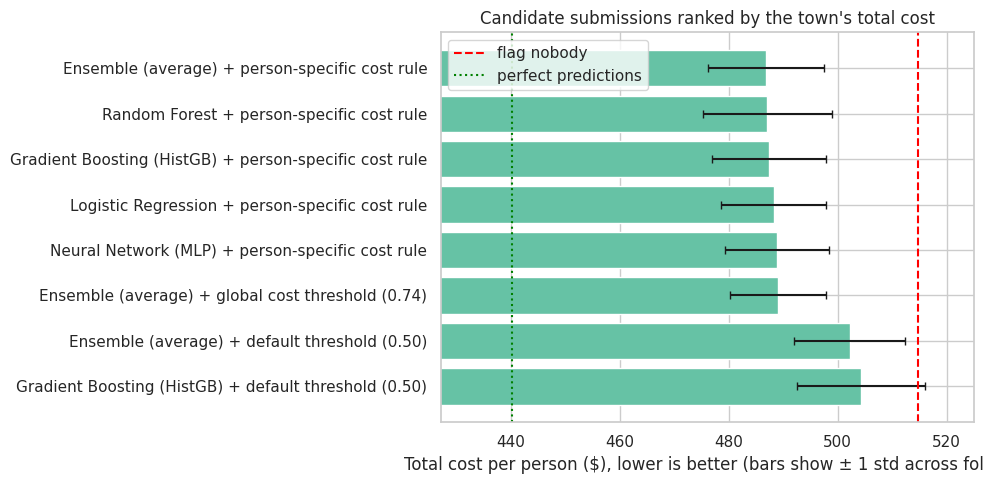

In [18]:
thr_train = person_threshold(p_u_train, p_v_train)
thr_test = person_threshold(p_u_test, p_v_test)

# Best single global threshold for the ensemble (searched on out-of-fold probabilities)
ens = "Ensemble (average)"
grid = np.linspace(0.01, 0.99, 99)
grid_costs = [town_cost(oof_proba[ens] >= t, y_arr, p_u_train, p_v_train)[0] for t in grid]
best_global = float(grid[int(np.argmin(grid_costs))])
print(f"Best single global threshold for the ensemble: {best_global:.2f}")
print(f"Person-specific thresholds range from {thr_train.min():.2f} to {thr_train.max():.2f}")

candidates = {}
for m in oof_proba:
    candidates[f"{m} + person-specific cost rule"] = (
        (oof_proba[m] > thr_train).astype(int), (test_proba[m] > thr_test).astype(int))
candidates[f"{ens} + global cost threshold ({best_global:.2f})"] = (
    (oof_proba[ens] >= best_global).astype(int), (test_proba[ens] >= best_global).astype(int))
candidates[f"{ens} + default threshold (0.50)"] = (
    (oof_proba[ens] >= 0.5).astype(int), (test_proba[ens] >= 0.5).astype(int))
candidates["Gradient Boosting (HistGB) + default threshold (0.50)"] = (
    (oof_proba["Gradient Boosting (HistGB)"] >= 0.5).astype(int),
    (test_proba["Gradient Boosting (HistGB)"] >= 0.5).astype(int))

def fold_costs(pred):
    """Cost per person in each CV fold for a set of out-of-fold predictions."""
    out = []
    for k in range(cv.get_n_splits()):
        m = fold_id == k
        out.append(town_cost(pred[m], y_arr[m], p_u_train[m], p_v_train[m])[0] / m.sum())
    return np.array(out)

n_test = len(test)
rows = []
for name, (pred_tr, pred_te) in candidates.items():
    tot, vs, hc = town_cost(pred_tr, y_arr, p_u_train, p_v_train)
    fc = fold_costs(pred_tr)
    rows.append({"candidate": name,
                 "cost per person ($)": tot / len(y_arr),
                 "± across folds": fc.std(),
                 "saving vs flag-nobody ($/person)": COST_NOBODY - tot / len(y_arr),
                 "est. total cost, test town ($)": tot / len(y_arr) * n_test,
                 "share flagged (train)": pred_tr.mean(),
                 "share flagged (test)": pred_te.mean(),
                 "accuracy": accuracy_score(y_arr, pred_tr)})

ranking = pd.DataFrame(rows).sort_values("cost per person ($)").reset_index(drop=True)
ranking.index = ranking.index + 1
ranking.index.name = "rank"
display(ranking.round(3))
print(f"Reference per person: flag nobody ${COST_NOBODY:,.2f} | perfect predictions ${COST_PERFECT:,.2f}")

fig, ax = plt.subplots(figsize=(10, 5))
r = ranking.iloc[::-1]
ax.barh(r["candidate"], r["cost per person ($)"], xerr=r["± across folds"], color="#66c2a5", capsize=3)
ax.axvline(COST_NOBODY, color="red", linestyle="--", label="flag nobody")
ax.axvline(COST_PERFECT, color="green", linestyle=":", label="perfect predictions")
ax.set_xlim(COST_PERFECT * 0.97, COST_NOBODY * 1.02)
ax.set_xlabel("Total cost per person ($), lower is better (bars show ± 1 std across folds)")
ax.set_title("Candidate submissions ranked by the town's total cost"); ax.legend()
plt.tight_layout(); plt.show()

**How to read the ranking:** if the gap between two candidates is smaller than the **±** value, they are statistically indistinguishable,
so the order of those candidates is partly luck. Say this in your critical evaluation. Also note that choosing the global threshold and picking the
top 5 from many candidates are both tuned on the same out-of-fold data, so the winners' costs are slightly optimistic.

## Step 12: Robustness check
The brief asks us to make sure the hospitalisation estimates are robust. Every candidate is re-scored under **different assumptions**
(hospitalisation risk halved or doubled, and a weaker or stronger vaccine). The decisions stay the same; only the scoring assumptions change.
If the ranking stays similar, our choice of best 5 does not depend heavily on one AI's numbers.

In [19]:
scenarios = {
    "Low risk (x0.5, VE 30%)": (0.5, 0.30),
    f"Consensus (x1, VE {VE:.0%})": (1.0, VE),
    "High risk (x2, VE 70%)": (2.0, 0.70),
}

robust = {}
for sc_name, (scale, ve_sc) in scenarios.items():
    pu_s, pv_s = hosp_probs(train, BASE, MULT, ve_sc, base_scale=scale)
    robust[sc_name] = {name: town_cost(pred_tr, y_arr, pu_s, pv_s)[0] / len(y_arr)
                       for name, (pred_tr, _) in candidates.items()}
    robust[sc_name]["(flag nobody)"] = town_cost(np.zeros(len(y_arr)), y_arr, pu_s, pv_s)[0] / len(y_arr)

robust_df = pd.DataFrame(robust)
rank_df = robust_df.rank(method="min").astype(int)
rank_df.columns = [c + " rank" for c in rank_df.columns]
display(pd.concat([robust_df.round(2), rank_df], axis=1).sort_values(rank_df.columns[1]))

,"Low risk (x0.5, VE 30%)","Consensus (x1, VE 55%)","High risk (x2, VE 70%)","Low risk (x0.5, VE 30%) rank","Consensus (x1, VE 55%) rank","High risk (x2, VE 70%) rank"
Ensemble (average) + person-specific cost rule,356.23,486.87,744.61,4,1,5
Random Forest + person-specific cost rule,355.43,487.04,746.85,1,2,7
Gradient Boosting (HistGB) + person-specific cost rule,357.30,487.44,744.13,5,3,4
Logistic Regression + person-specific cost rule,357.44,488.24,746.32,6,4,6
Neural Network (MLP) + person-specific cost rule,360.46,488.93,742.07,7,5,2
Ensemble (average) + global cost threshold (0.74),355.53,489.06,752.96,2,6,8
Ensemble (average) + default threshold (0.50),381.13,502.20,739.63,8,7,1
Gradient Boosting (HistGB) + default threshold (0.50),382.77,504.29,742.66,9,8,3
(flag nobody),355.88,514.74,832.47,3,9,9


## Step 13: Explainable AI (XAI)
Three views of what the model has learned (the brief allows polishing these after the hackathon, but a first version should exist today):
1. **Permutation importance:** how much worse the model gets when one feature is shuffled.
2. **Partial dependence:** how the predicted chance of accepting a vaccine changes as one feature changes.
3. **Who gets flagged:** which kinds of people the best submission sends vaccines to.

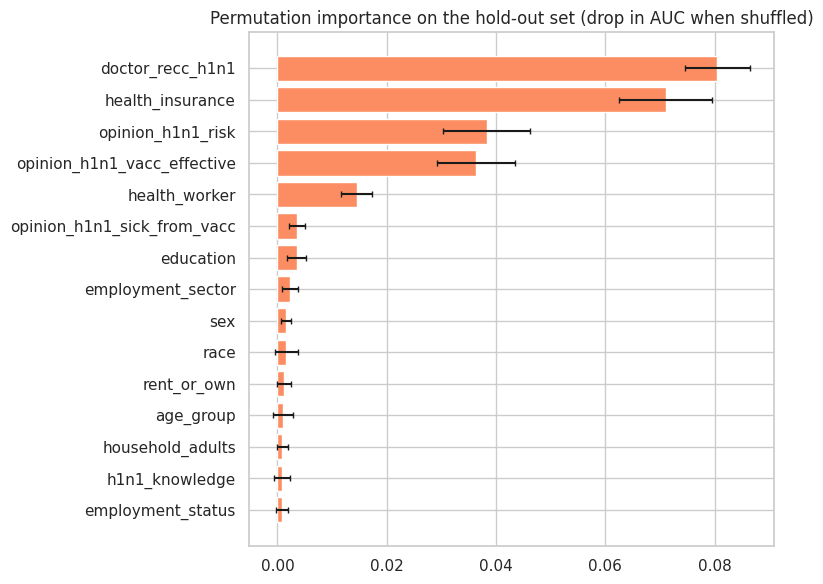

In [20]:
best_hgb = searches["Gradient Boosting (HistGB)"].best_estimator_      # fitted on the 80% training part

perm = permutation_importance(best_hgb, X_val, y_val, scoring="roc_auc",
                              n_repeats=10, random_state=RANDOM_STATE, n_jobs=-1)
imp = pd.Series(perm.importances_mean, index=X_val.columns)
imp_std = pd.Series(perm.importances_std, index=X_val.columns)
top = imp.sort_values(ascending=False).head(15)

fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(top.index[::-1], top.values[::-1], xerr=imp_std[top.index].values[::-1], color="#fc8d62", capsize=2)
ax.set_title("Permutation importance on the hold-out set (drop in AUC when shuffled)")
plt.tight_layout(); plt.show()

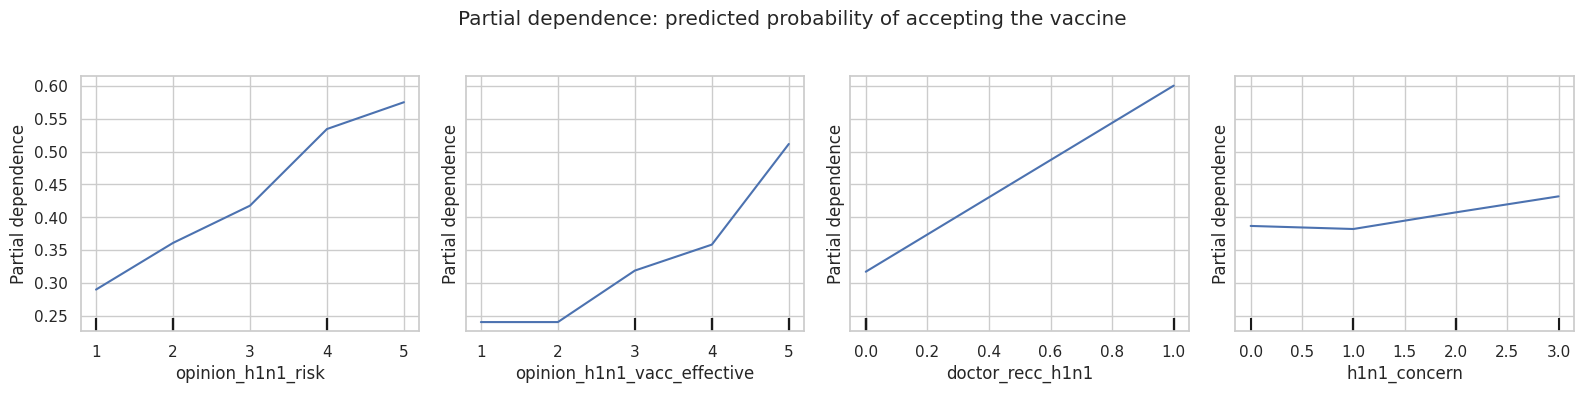

In [21]:
pdp_features = ["opinion_h1n1_risk", "opinion_h1n1_vacc_effective", "doctor_recc_h1n1", "h1n1_concern"]

fig, ax = plt.subplots(1, len(pdp_features), figsize=(16, 3.8), sharey=True)
PartialDependenceDisplay.from_estimator(best_hgb, X_val, pdp_features, kind="average",
                                        grid_resolution=15, ax=ax)
fig.suptitle("Partial dependence: predicted probability of accepting the vaccine", y=1.03)
plt.tight_layout(); plt.show()

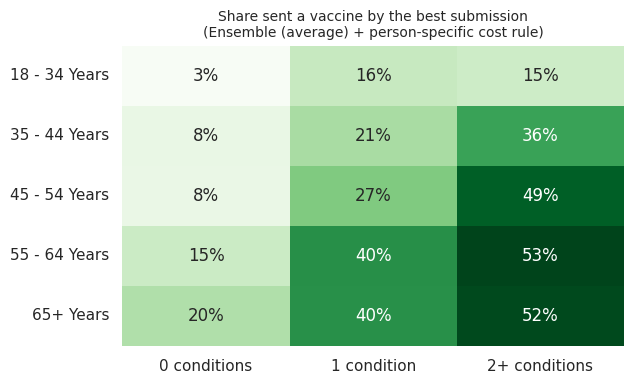

In [22]:
# Who does the best submission send vaccines to? (test set)
best_name = ranking.iloc[0]["candidate"]
flag_test = candidates[best_name][1]
who = pd.DataFrame({"age_group": test["age_group"].values,
                    "chronic_conditions": np.clip(test["number_chronic_med_conditions"].fillna(0).values, 0, 2),
                    "flagged": flag_test})
table = who.pivot_table(index="age_group", columns="chronic_conditions", values="flagged", aggfunc="mean").reindex(AGE_ORDER)
table.columns = ["0 conditions", "1 condition", "2+ conditions"]

fig, ax = plt.subplots(figsize=(6.5, 4))
sns.heatmap(table, annot=True, fmt=".0%", cmap="Greens", ax=ax, cbar=False)
ax.set_title(f"Share sent a vaccine by the best submission\n({best_name})", fontsize=10)
ax.set_ylabel(""); plt.tight_layout(); plt.show()

## Step 14: Plain-English summary for non-experts
Use this for your summary slide (stakeholders want conclusions, not data science).

In [23]:
best = ranking.iloc[0]
saving_pp = COST_NOBODY - best["cost per person ($)"]
print(f"Best submission: {best['candidate']}")
print(f"- Sending vaccines to everyone who wants one is not necessary: we only send them to about "
      f"{best['share flagged (test)']:.0%} of people, chosen because a vaccine helps them most and they are likely to use it.")
print(f"- Estimated cost: ${best['cost per person ($)']:.0f} per person, against ${COST_NOBODY:.0f} if we sent no vaccines "
      f"(a saving of about ${saving_pp:.0f} per person, {saving_pp / COST_NOBODY:.1%}).")
print(f"- For a town the size of the test set ({n_test:,} people) that is roughly ${saving_pp * n_test:,.0f} saved.")
print(f"- The best possible result with perfect knowledge would be ${COST_PERFECT:.0f} per person, so the model captures "
      f"{saving_pp / (COST_NOBODY - COST_PERFECT):.0%} of the available saving.")
print("- The main reason: money is only saved when a vaccine reaches someone who will use it AND who is at real risk "
      "of hospitalisation (older people and people with chronic conditions). A wasted vaccine costs $500 for nothing.")
print("- Caveat: these results depend on the estimated hospitalisation risks; see the robustness table (Step 12).")

Best submission: Ensemble (average) + person-specific cost rule
- Sending vaccines to everyone who wants one is not necessary: we only send them to about 19% of people, chosen because a vaccine helps them most and they are likely to use it.
- Estimated cost: $487 per person, against $515 if we sent no vaccines (a saving of about $28 per person, 5.4%).
- For a town the size of the test set (4,749 people) that is roughly $132,399 saved.
- The best possible result with perfect knowledge would be $440 per person, so the model captures 37% of the available saving.
- The main reason: money is only saved when a vaccine reaches someone who will use it AND who is at real risk of hospitalisation (older people and people with chronic conditions). A wasted vaccine costs $500 for nothing.
- Caveat: these results depend on the estimated hospitalisation risks; see the robustness table (Step 12).


## Step 15: Save the best 5 submission files
Files are named `challenge_submission_group_X_order_Y.csv`, where **X = your group number** and **Y = rank (1 = lowest cost)**.
**Set `GROUP_NUMBER` to your real group number before running.**

In [24]:
GROUP_NUMBER = 0        # <-- CHANGE THIS to your group number

os.makedirs("submissions", exist_ok=True)
for f in os.listdir("submissions"):
    os.remove(os.path.join("submissions", f))

top5 = ranking.head(5)
saved = []
for order, row in top5.iterrows():
    pred_te = candidates[row["candidate"]][1]
    sub = pd.DataFrame({ID: test[ID].values, TARGET: pred_te.astype(int)})

    # safety checks against the example file
    assert list(sub.columns) == list(example.columns), "Column names differ from example"
    assert len(sub) == len(example), "Row count differs from example"
    assert (sub[ID].values == example[ID].values).all(), "ID order differs from example"
    assert sub[TARGET].isin([0, 1]).all()

    fname = f"challenge_submission_group_{GROUP_NUMBER}_order_{order}.csv"
    sub.to_csv(os.path.join("submissions", fname), index=False)
    saved.append(fname)
    print(f"{fname}  <-  {row['candidate']}  (cost/person ${row['cost per person ($)']:.2f} "
          f"± {row['± across folds']:.2f}, flags {sub[TARGET].mean():.1%} of people)")

ranking.to_csv("ranking_summary.csv")          # keep for your documentation
shutil.make_archive("submissions", "zip", "submissions")
print("\nSaved", len(saved), "files and submissions.zip")

challenge_submission_group_0_order_1.csv  <-  Ensemble (average) + person-specific cost rule  (cost/person $486.87 ± 10.72, flags 18.5% of people)
challenge_submission_group_0_order_2.csv  <-  Random Forest + person-specific cost rule  (cost/person $487.04 ± 11.86, flags 17.6% of people)
challenge_submission_group_0_order_3.csv  <-  Gradient Boosting (HistGB) + person-specific cost rule  (cost/person $487.44 ± 10.45, flags 18.9% of people)
challenge_submission_group_0_order_4.csv  <-  Logistic Regression + person-specific cost rule  (cost/person $488.24 ± 9.68, flags 18.2% of people)
challenge_submission_group_0_order_5.csv  <-  Neural Network (MLP) + person-specific cost rule  (cost/person $488.93 ± 9.55, flags 21.6% of people)

Saved 5 files and submissions.zip


In [25]:
# Download the zip (Colab only)
try:
    from google.colab import files
    files.download("submissions.zip")
except ImportError:
    print("Not running in Colab: the files are in the 'submissions' folder.")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>